In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df=pd.read_csv("../python/Beauty_Wellness_Cleaned_Data.csv")

In [5]:
print("shape of dataset",df.shape)

shape of dataset (4839, 9)


In [6]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesAmount
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


In [7]:
df.info

<bound method DataFrame.info of       InvoiceNo StockCode                          Description  Quantity  \
0        536365    85123A   WHITE HANGING HEART T-LIGHT HOLDER         6   
1        536365     71053                  WHITE METAL LANTERN         6   
2        536365    84406B       CREAM CUPID HEARTS COAT HANGER         8   
3        536365    84029G  KNITTED UNION FLAG HOT WATER BOTTLE         6   
4        536365    84029E       RED WOOLLY HOTTIE WHITE HEART.         6   
...         ...       ...                                  ...       ...   
4834     536836     21843             RED RETROSPOT CAKE STAND         2   
4835     536836     21531         RED RETROSPOT SUGAR JAM BOWL         2   
4836     536836     21539            RED RETROSPOT BUTTER DISH         3   
4837     536836     22198                 LARGE POPCORN HOLDER         2   
4838     536836     22197                 SMALL POPCORN HOLDER         2   

              InvoiceDate  UnitPrice  CustomerID       

In [8]:
df.describe()

,InvoiceNo,Quantity,UnitPrice,CustomerID,SalesAmount
count,4839.000000,4839.000000,4839.000000,3646.000000,4839.000000
mean,536592.402769,11.610250,3.816654,15897.113275,21.443213
std,121.940981,59.331614,13.413101,1727.334761,62.849136
min,536365.000000,1.000000,0.100000,12431.000000,0.290000
25%,536532.000000,1.000000,1.250000,14606.000000,4.210000
50%,536592.000000,3.000000,2.510000,15862.000000,10.500000
75%,536653.000000,12.000000,4.210000,17841.000000,17.850000
max,536836.000000,2880.000000,607.490000,18239.000000,1627.200000


In [9]:
print(df.isnull().sum())

InvoiceNo         0
StockCode         0
Description       0
Quantity          0
InvoiceDate       0
UnitPrice         0
CustomerID     1193
Country           0
SalesAmount       0
dtype: int64


In [10]:
print("Mean:")
print(df[["Quantity", "UnitPrice", "SalesAmount"]].mean())

print("\nMedian:")
print(df[["Quantity", "UnitPrice", "SalesAmount"]].median())

print("\nMode:")
print(df[["Quantity", "UnitPrice", "SalesAmount"]].mode().iloc[0])

Mean:
Quantity       11.610250
UnitPrice       3.816654
SalesAmount    21.443213
dtype: float64

Median:
Quantity        3.00
UnitPrice       2.51
SalesAmount    10.50
dtype: float64

Mode:
Quantity        1.00
UnitPrice       1.25
SalesAmount    15.00
Name: 0, dtype: float64


In [11]:
print("Standard Deviation:")
print(df[["Quantity", "UnitPrice", "SalesAmount"]].std())

Standard Deviation:
Quantity       59.331614
UnitPrice      13.413101
SalesAmount    62.849136
dtype: float64


In [12]:
print("Skewness:")
print(df[["Quantity", "UnitPrice", "SalesAmount"]].skew())

Skewness:
Quantity       32.884309
UnitPrice      36.985949
SalesAmount    14.232945
dtype: float64


In [13]:
correlation = df[["Quantity", "UnitPrice", "SalesAmount"]].corr()

print(correlation)

             Quantity  UnitPrice  SalesAmount
Quantity     1.000000  -0.028742     0.559589
UnitPrice   -0.028742   1.000000     0.208215
SalesAmount  0.559589   0.208215     1.000000


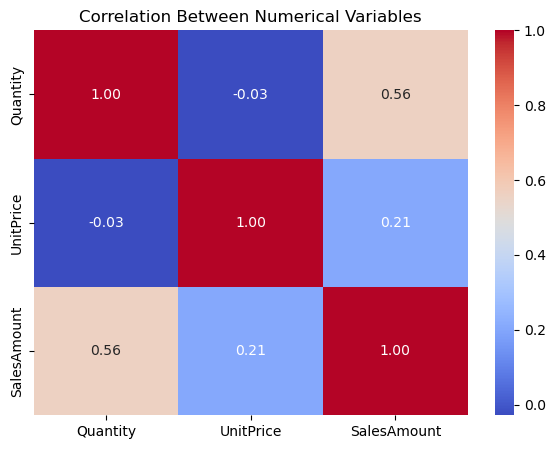

In [14]:
plt.figure(figsize=(7, 5))

sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")

plt.title("Correlation Between Numerical Variables")
plt.show()

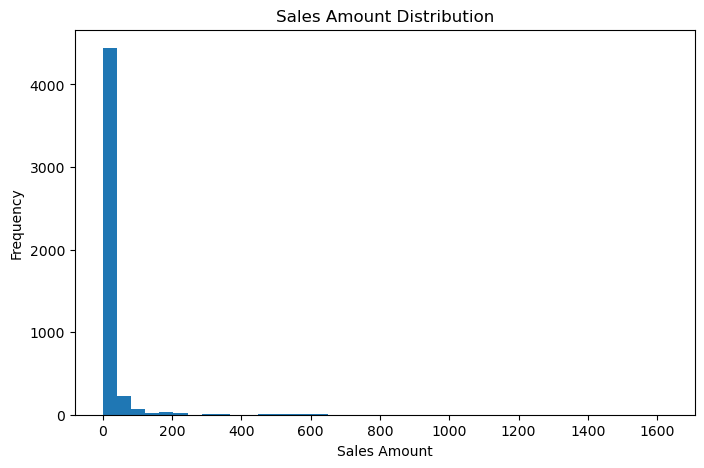

In [15]:
plt.figure(figsize=(8, 5))

plt.hist(df["SalesAmount"], bins=40)

plt.title("Sales Amount Distribution")
plt.xlabel("Sales Amount")
plt.ylabel("Frequency")

plt.show()

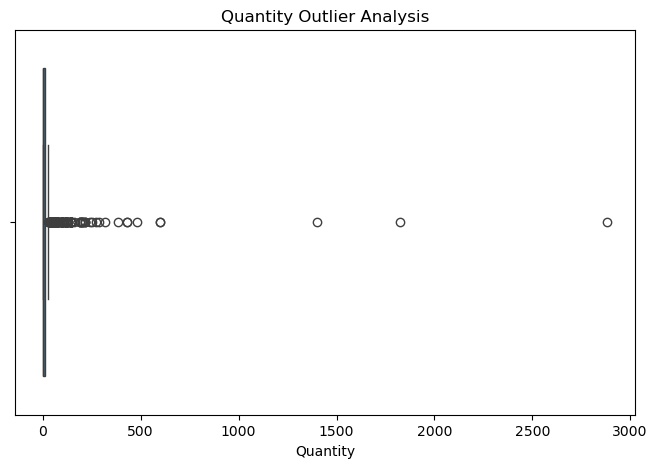

In [16]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=df["Quantity"])

plt.title("Quantity Outlier Analysis")
plt.xlabel("Quantity")

plt.show()

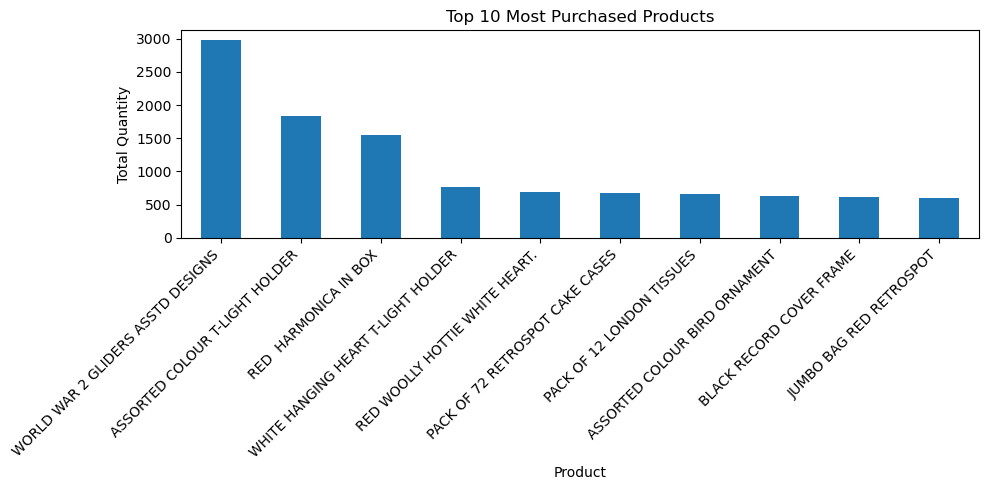

In [17]:
top_products = df.groupby("Description")["Quantity"].sum()
top_products = top_products.sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 5))

top_products.plot(kind="bar")

plt.title("Top 10 Most Purchased Products")
plt.xlabel("Product")
plt.ylabel("Total Quantity")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

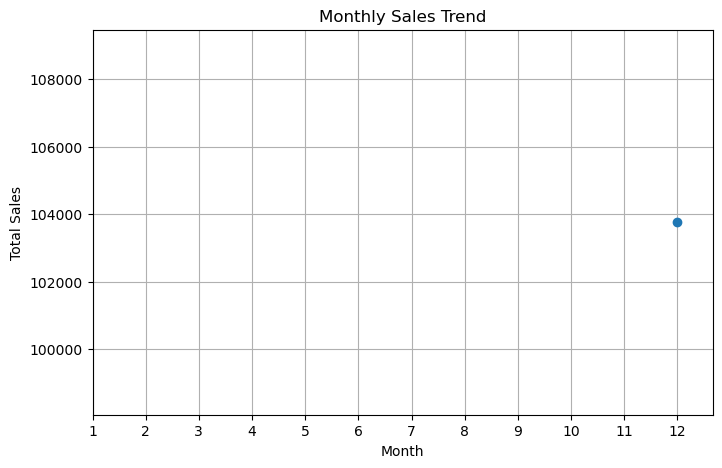

In [18]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["Month"] = df["InvoiceDate"].dt.month

monthly_sales = df.groupby("Month")["SalesAmount"].sum()

plt.figure(figsize=(8, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")

plt.xticks(range(1, 13))
plt.grid()
plt.show()

In [19]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

df["Year"] = df["InvoiceDate"].dt.year
df["Month"] = df["InvoiceDate"].dt.month
df["Day"] = df["InvoiceDate"].dt.day
df["DayOfWeek"] = df["InvoiceDate"].dt.dayofweek
df["Hour"] = df["InvoiceDate"].dt.hour

df["IsWeekend"] = df["DayOfWeek"].isin([5, 6])

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesAmount,Month,Year,Day,DayOfWeek,Hour,IsWeekend
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,2010,1,2,8,False
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,1,2,8,False
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,2010,1,2,8,False
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,1,2,8,False
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,1,2,8,False


In [20]:
df["InvoiceTotal"] = df.groupby("InvoiceNo")["SalesAmount"].transform("sum")

df["BasketQuantity"] = df.groupby("InvoiceNo")["Quantity"].transform("sum")

df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesAmount,Month,Year,Day,DayOfWeek,Hour,IsWeekend,InvoiceTotal,BasketQuantity
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,2010,1,2,8,False,139.12,40
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,1,2,8,False,139.12,40
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,2010,1,2,8,False,139.12,40
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,1,2,8,False,139.12,40
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,2010,1,2,8,False,139.12,40


In [21]:
customer_df = df.dropna(subset=["CustomerID"])

customer_features = customer_df.groupby("CustomerID").agg(
    PurchaseFrequency=("InvoiceNo", "nunique"),
    CustomerSpend=("SalesAmount", "sum"),
    AverageOrderValue=("InvoiceTotal", "mean"),
    ProductDiversity=("Description", "nunique")
)

customer_features.head(10)

,PurchaseFrequency,CustomerSpend,AverageOrderValue,ProductDiversity
CustomerID,,,,
12431.0,1,358.25,358.25,14
12433.0,1,1919.14,1919.14,73
12583.0,1,855.86,855.86,20
12662.0,1,261.48,261.48,15
12748.0,2,9.20,4.60,2
12791.0,1,192.60,192.60,2
12838.0,1,390.79,390.79,59
12855.0,1,38.10,38.10,3
12868.0,1,203.30,203.30,12


In [22]:
latest_date = df["InvoiceDate"].max()

last_purchase = customer_df.groupby("CustomerID")["InvoiceDate"].max()

customer_features["RecencyDays"] = (
    latest_date - last_purchase
).dt.days

customer_features.head(10)

,PurchaseFrequency,CustomerSpend,AverageOrderValue,ProductDiversity,RecencyDays
CustomerID,,,,,
12431.0,1,358.25,358.25,14,1
12433.0,1,1919.14,1919.14,73,1
12583.0,1,855.86,855.86,20,1
12662.0,1,261.48,261.48,15,1
12748.0,2,9.20,4.60,2,0
12791.0,1,192.60,192.60,2,1
12838.0,1,390.79,390.79,59,1
12855.0,1,38.10,38.10,3,0
12868.0,1,203.30,203.30,12,1


In [23]:
numeric_columns = ["Quantity", "UnitPrice", "SalesAmount"]

df[numeric_columns].head()

,Quantity,UnitPrice,SalesAmount
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [24]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

df[["Quantity_Normalized",
    "UnitPrice_Normalized",
    "SalesAmount_Normalized"]] = scaler.fit_transform(df[numeric_columns])

df[["Quantity_Normalized",
    "UnitPrice_Normalized",
    "SalesAmount_Normalized"]].head()

,Quantity_Normalized,UnitPrice_Normalized,SalesAmount_Normalized
0,0.001737,0.004034,0.009226
1,0.001737,0.005417,0.012324
2,0.002431,0.004363,0.013344
3,0.001737,0.005417,0.012324
4,0.001737,0.005417,0.012324


In [25]:
df["Country_Code"] = df["Country"].astype("category").cat.codes

df[["Country", "Country_Code"]].head(10)

,Country,Country_Code
0,United Kingdom,6
1,United Kingdom,6
2,United Kingdom,6
3,United Kingdom,6
4,United Kingdom,6
5,United Kingdom,6
6,United Kingdom,6
7,United Kingdom,6
8,United Kingdom,6
9,United Kingdom,6


In [26]:
df["IsWeekend_Code"] = df["IsWeekend"].astype(int)

df[["IsWeekend", "IsWeekend_Code"]].head(10)

,IsWeekend,IsWeekend_Code
0,False,0
1,False,0
2,False,0
3,False,0
4,False,0
5,False,0
6,False,0
7,False,0
8,False,0
9,False,0


In [27]:
print("Updated Dataset Shape:", df.shape)

df.head()

Updated Dataset Shape: (4839, 22)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,SalesAmount,Month,...,DayOfWeek,Hour,IsWeekend,InvoiceTotal,BasketQuantity,Quantity_Normalized,UnitPrice_Normalized,SalesAmount_Normalized,Country_Code,IsWeekend_Code
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30,12,...,2,8,False,139.12,40,0.001737,0.004034,0.009226,6,0
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,...,2,8,False,139.12,40,0.001737,0.005417,0.012324,6,0
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00,12,...,2,8,False,139.12,40,0.002431,0.004363,0.013344,6,0
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,...,2,8,False,139.12,40,0.001737,0.005417,0.012324,6,0
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34,12,...,2,8,False,139.12,40,0.001737,0.005417,0.012324,6,0


In [28]:
print("Total Sales:", df["SalesAmount"].sum())

print("Average Sales:", df["SalesAmount"].mean())

print("Maximum Sales:", df["SalesAmount"].max())

print("Minimum Sales:", df["SalesAmount"].min())

Total Sales: 103763.70999999999
Average Sales: 21.443213473858233
Maximum Sales: 1627.2
Minimum Sales: 0.29


In [29]:
country_sales = df.groupby("Country")["SalesAmount"].sum()

top_countries = country_sales.sort_values(ascending=False).head(5)

print(top_countries)

Country
United Kingdom    99598.50
Norway             1919.14
France              855.86
EIRE                577.88
Australia           358.25
Name: SalesAmount, dtype: float64


In [30]:
top_customers = customer_features.sort_values(
    by="CustomerSpend", ascending=False
).head(5)

print(top_customers[["CustomerSpend", "PurchaseFrequency"]])

            CustomerSpend  PurchaseFrequency
CustomerID                                  
15061.0           9407.34                  6
13777.0           6585.16                  7
17850.0           5391.21                 34
16029.0           4271.52                  3
16210.0           2474.74                  1


In [31]:
correlation = df[
    ["Quantity", "UnitPrice", "SalesAmount"]
].corr()

print(correlation)

             Quantity  UnitPrice  SalesAmount
Quantity     1.000000  -0.028742     0.559589
UnitPrice   -0.028742   1.000000     0.208215
SalesAmount  0.559589   0.208215     1.000000


In [32]:
print("Final Dataset Shape:", df.shape)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

Final Dataset Shape: (4839, 22)

Missing Values:
InvoiceNo                    0
StockCode                    0
Description                  0
Quantity                     0
InvoiceDate                  0
UnitPrice                    0
CustomerID                1193
Country                      0
SalesAmount                  0
Month                        0
Year                         0
Day                          0
DayOfWeek                    0
Hour                         0
IsWeekend                    0
InvoiceTotal                 0
BasketQuantity               0
Quantity_Normalized          0
UnitPrice_Normalized         0
SalesAmount_Normalized       0
Country_Code                 0
IsWeekend_Code               0
dtype: int64

Duplicate Rows: 0


In [33]:
df.to_csv("Week4_Final_EDA_Dataset.csv", index=False)

print("Final dataset saved successfully!")

Final dataset saved successfully!


In [34]:
customer_features.to_csv("Week4_Customer_Analysis.csv")

print("Customer analysis saved successfully!")

Customer analysis saved successfully!


In [35]:
df.describe().to_csv("Week4_Statistical_Summary.csv")

print("Statistical summary saved successfully!")

Statistical summary saved successfully!


In [36]:
print("WEEK 4 TASK COMPLETED")
print("Exploratory Data Analysis and Feature Engineering")
print("All results have been saved successfully.")

WEEK 4 TASK COMPLETED
Exploratory Data Analysis and Feature Engineering
All results have been saved successfully.
